# Analisis Sentimen - Komentar YouTube (Bahasa Indonesia)
**Nama**: Asep Haryana Saputra

## 1. Impor Pustaka

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, LSTM, Dense, Bidirectional, Dropout, SpatialDropout1D, BatchNormalization
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import resample
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.pipeline import make_pipeline
from typing import Optional, Tuple, List, Dict
from tqdm.auto import tqdm

print(f"Versi TensorFlow: {tf.__version__}")



2026-02-11 02:59:37.518461: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-11 02:59:37.755197: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-02-11 02:59:38.850826: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Versi TensorFlow: 2.20.0


## 2. Memuat Data & Pra-pemrosesan (Lanjutan)
**Kelas Target**:
- 0: **Negatif**
- 1: **Positif**
- 2: **Spam**

In [2]:
"""
Modul Pra-pemrosesan dan Pelabelan Otomatis untuk Analisis Komentar YouTube
Dioptimalkan untuk struktur dataset spesifik
Menggunakan Pustaka Transformers untuk Pelabelan Akurasi Tinggi
"""

import pandas as pd
import numpy as np
import re
import os
from sklearn.utils import resample
from typing import Optional, Tuple, List, Dict
from transformers import pipeline # Impor Transformers

class YouTubeCommentsPreprocessor:
    """Pipeline pra-pemrosesan dan pelabelan otomatis untuk dataset komentar YouTube."""
    
    def __init__(self, filepath: str, random_seed: int = 42):
        """
        Inisialisasi preprocessor dengan path file dataset.
        """
        self.filepath = filepath
        self.random_seed = random_seed
        self.df = None
        self.labeled_data = None
        
        # Inisialisasi Pustaka Sentimen (Transformers)
        print("[INFO] Memuat Model Sentimen Transformers (Indonesian RoBERTa)...")
        try:
            self.sentiment_model = pipeline(
                "sentiment-analysis", 
                model="w11wo/indonesian-roberta-base-sentiment-classifier",
                tokenizer="w11wo/indonesian-roberta-base-sentiment-classifier"
            )
            print("[INFO] Model sentimen berhasil dimuat")
        except Exception as e:
            print(f"[ERROR] Gagal memuat model transformer: {e}")
            self.sentiment_model = None
        
        # Keyword Spam Minimal (Fokus pada promosi eksplisit)
        self.spam_keywords = [
            'jual', 'obat', 'promo', 'sub4sub', 'giveaway', 'hadiah', 'klik',
            'top up', 'wa ', '08', 'judol', 'slot', 'donasi', 'saweria', 'wa:',
            'order', 'murah', 'diskon', 'cek ig', 'cek link', 'bio'
        ]
        
        # Pola khusus untuk deteksi spam (URL dan Nomor Telepon Eksplisit)
        self.spam_patterns = [
            r'https?://\S+',  # URL
            r'\d{10,}',       # Nomor Telepon
        ]
        
        # Pemetaan Label
        self.label_map = {
            0: 'negative',
            1: 'positive',
            2: 'spam',
            -1: 'unlabeled'
        }
    
    def load_dataset(self) -> pd.DataFrame:
        if not os.path.exists(self.filepath):
            raise FileNotFoundError(f"File dataset tidak ditemukan di: {self.filepath}")
        self.df = pd.read_csv(self.filepath)
        print(f"[INFO] Memuat {len(self.df):,} baris dari {self.filepath}")
        return self.df
    
    def filter_columns(self) -> pd.DataFrame:
        keep_columns = ['text', 'votes', 'heart']
        missing_cols = [col for col in keep_columns if col not in self.df.columns]
        if missing_cols:
            raise ValueError(f"Kolom wajib hilang: {missing_cols}")
        if 'label' in self.df.columns:
            # Kita akan menimpa label yang ada untuk memastikan kualitas library
            print("[INFO] Menimpa label yang ada dengan prediksi library")
        self.df = self.df[keep_columns].copy()
        return self.df
    
    @staticmethod
    def clean_vote_count(vote_str: str) -> float:
        if pd.isna(vote_str) or vote_str == '': return 0.0
        vote_str = str(vote_str).strip().lower()
        multiplier = 1
        if 'rb' in vote_str: multiplier = 1000
        elif 'k' in vote_str: multiplier = 1000
        elif 'm' in vote_str: multiplier = 1_000_000
        vote_str = vote_str.replace('rb', '').replace('k', '').replace('m', '')
        vote_str = vote_str.replace(',', '').replace(' ', '')
        numeric_match = re.search(r'[\d.]+', vote_str)
        if numeric_match:
            try: return float(numeric_match.group()) * multiplier
            except: return 0.0
        return 0.0
    
    def standardize_heart_reaction(self) -> pd.DataFrame:
        heart_mapping = {'true': 1, 'false': 0, '1': 1, '0': 0, 'yes': 1, 'no': 0}
        self.df['heart'] = (
            self.df['heart'].astype(str).str.strip().str.lower()
            .map(heart_mapping).fillna(0).astype(int)
        )
        return self.df
    
    def _contains_spam_pattern(self, text: str) -> bool:
        text_lower = str(text).lower()
        for pattern in self.spam_patterns:
            if re.search(pattern, text_lower, re.IGNORECASE): return True
        return False
    
    def auto_label_comments(self, use_existing: bool = False) -> pd.DataFrame:
        """
        Melabeli komentar menggunakan library Transformers + Heuristik Spam.
        """
        print("[INFO] Menerapkan pelabelan otomatis berbasis library (Transformers)...")
        print("[PERINGATAN] Proses ini akan memproses komentar secara batch. Ini mungkin memakan waktu 5-15 menit.")
        
        if self.sentiment_model is None:
            raise ValueError("Model belum dimuat. Pastikan library transformers terinstal.")

        # Siapkan teks
        texts = self.df['text'].fillna("").astype(str).tolist()
        processed_labels = []
        
        # Pemetaan biner untuk output transformers
        # Model w11wo mengeluarkan: 'positive', 'neutral', 'negative'
        trans_map = {
            'positive': 1,
            'negative': 0,
            'neutral': -1 # Anggap unlabeled kecuali spam menangkapnya
        }

        # Proses dalam batch untuk efisiensi
        batch_size = 32
        for i in range(0, len(texts), batch_size):
            batch = texts[i:i + batch_size]
            
            # Dapatkan prediksi untuk batch
            try:
                preds = self.sentiment_model(batch, truncation=True, max_length=512)
            except Exception as e:
                print(f"Batch {i} gagal: {e}")
                preds = [{'label': 'neutral'}] * len(batch)
            
            for j, p in enumerate(preds):
                comment = batch[j]
                comment_lower = comment.lower()
                
                # Cek SPAM terlebih dahulu (Heuristik)
                is_spam = False
                if self._contains_spam_pattern(comment_lower):
                    is_spam = True
                elif any(k in comment_lower for k in self.spam_keywords):
                    is_spam = True
                elif len(comment_lower.strip()) < 3:
                    is_spam = True
                
                if is_spam:
                    processed_labels.append(2) # Spam
                else:
                    # Gunakan prediksi Transformer
                    sent_label = p['label']
                    processed_labels.append(trans_map.get(sent_label, -1))
            
            if (i // batch_size) % 10 == 0:
                print(f"Memproses {i + len(batch)} / {len(texts)} komentar...")

        self.df['label'] = processed_labels
        
        # Statistik
        label_counts = self.df['label'].value_counts()
        print(f"[INFO] Pelabelan otomatis selesai:")
        for l, count in label_counts.items():
            name = self.label_map.get(l, "Unknown")
            print(f"  - {name}: {count}")
        
        return self.df
    
    def remove_unlabeled_comments(self) -> pd.DataFrame:
        if 'label' not in self.df.columns: raise ValueError("Tidak ada kolom label")
        self.labeled_data = self.df[self.df['label'] != -1].copy()
        print(f"[INFO] Menyimpan {len(self.labeled_data):,} komentar berlabel (tidak termasuk Netral/Unlabeled)")
        return self.labeled_data
    
    def balance_dataset(self, strategy: str = 'upsample', min_samples: int = None) -> pd.DataFrame:
        if self.labeled_data is None: raise ValueError("Tidak ada data berlabel")
        
        df_pos = self.labeled_data[self.labeled_data['label'] == 1]
        df_neg = self.labeled_data[self.labeled_data['label'] == 0]
        df_spam = self.labeled_data[self.labeled_data['label'] == 2]
        
        print(f"Distribusi sebelum penyeimbangan: Pos={len(df_pos)}, Neg={len(df_neg)}, Spam={len(df_spam)}")
        
        target = min_samples if min_samples else max(len(df_pos), len(df_neg), len(df_spam))
        
        if strategy == 'upsample':
            df_pos = resample(df_pos, replace=True, n_samples=target, random_state=42)
            df_neg = resample(df_neg, replace=True, n_samples=target, random_state=42)
            df_spam = resample(df_spam, replace=True, n_samples=target, random_state=42)
            self.labeled_data = pd.concat([df_pos, df_neg, df_spam])
            
        self.labeled_data = self.labeled_data.sample(frac=1, random_state=42).reset_index(drop=True)
        return self.labeled_data
    
    def clean_text_column(self) -> pd.DataFrame:
        def clean_text(text: str) -> str:
            if pd.isna(text): return ""
            text = str(text)
            text = re.sub(r'https?://\S+|www\.\S+', '', text)
            text = re.sub(r'@\w+', '', text)
            text = ' '.join(text.split())
            text = re.sub(r'[^\w\s\u00C0-\u017F]', ' ', text)
            return text.strip()
        
        target_df = self.labeled_data if self.labeled_data is not None else self.df
        target_df['text_clean'] = target_df['text'].apply(clean_text)
        return target_df

    def get_dataset_summary(self) -> Dict:
        if self.labeled_data is None: return {}
        return {
            'total': len(self.labeled_data),
            'distribution': self.labeled_data['label'].value_counts().to_dict()
        }
    
    def export_processed_data(self, output_path: str = None) -> str:
        if self.labeled_data is None: raise ValueError("Tidak ada data")
        if not output_path: output_path = "processed_data_transformers.csv"
        self.labeled_data.to_csv(output_path, index=False)
        return output_path

    def run_pipeline(self, balance_strategy='upsample', min_samples=None, export=True):
        print("Menjalankan Pipeline berbasis Transformers...")
        self.load_dataset()
        self.filter_columns()
        self.df['votes'] = self.df['votes'].apply(self.clean_vote_count)
        self.standardize_heart_reaction()
        self.auto_label_comments()
        self.remove_unlabeled_comments()
        self.clean_text_column()
        self.balance_dataset(balance_strategy, min_samples)
        if export: self.export_processed_data()
        return self.labeled_data, self.get_dataset_summary() 



In [3]:

# Eksekusi Pipeline Pra-pemrosesan
preprocessor = YouTubeCommentsPreprocessor(
    filepath='dataset_youtube.csv',
    random_seed=42
)

# Jalankan pipeline (Penyeimbangan upsample diaktifkan, ekspor dinonaktifkan untuk aliran notebook ini)
df_clean, summary = preprocessor.run_pipeline(
    balance_strategy='upsample',
    export=False
)

print("\nContoh Data:")
display(df_clean.head())



[INFO] Memuat Model Sentimen Transformers (Indonesian RoBERTa)...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: w11wo/indonesian-roberta-base-sentiment-classifier
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[INFO] Model sentimen berhasil dimuat
Menjalankan Pipeline berbasis Transformers...
[INFO] Memuat 15,500 baris dari dataset_youtube.csv
[INFO] Menerapkan pelabelan otomatis berbasis library (Transformers)...
[PERINGATAN] Proses ini akan memproses komentar secara batch. Ini mungkin memakan waktu 5-15 menit.
Memproses 32 / 15500 komentar...


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Memproses 352 / 15500 komentar...
Memproses 672 / 15500 komentar...
Memproses 992 / 15500 komentar...
Memproses 1312 / 15500 komentar...
Memproses 1632 / 15500 komentar...
Memproses 1952 / 15500 komentar...
Memproses 2272 / 15500 komentar...
Memproses 2592 / 15500 komentar...
Memproses 2912 / 15500 komentar...
Memproses 3232 / 15500 komentar...
Memproses 3552 / 15500 komentar...
Memproses 3872 / 15500 komentar...
Memproses 4192 / 15500 komentar...
Memproses 4512 / 15500 komentar...
Memproses 4832 / 15500 komentar...
Memproses 5152 / 15500 komentar...
Memproses 5472 / 15500 komentar...
Memproses 5792 / 15500 komentar...
Memproses 6112 / 15500 komentar...
Memproses 6432 / 15500 komentar...
Memproses 6752 / 15500 komentar...
Memproses 7072 / 15500 komentar...
Memproses 7392 / 15500 komentar...
Memproses 7712 / 15500 komentar...
Memproses 8032 / 15500 komentar...
Memproses 8352 / 15500 komentar...
Memproses 8672 / 15500 komentar...
Memproses 8992 / 15500 komentar...
Memproses 9312 / 15500 

,text,votes,heart,label,text_clean
0,Wakakaka lucu kalii anjayyy,1.0,0,1,Wakakaka lucu kalii anjayyy
1,Challenge tiktok no bra viral..\nLangsung di c...,0.0,0,2,Challenge tiktok no bra viral Langsung di ce...
2,Up,0.0,0,2,Up
3,Up,0.0,0,2,Up
4,Anjayyy kok dilarang\nAnjayyy kok dipidana \nA...,34.0,0,2,Anjayyy kok dilarang Anjayyy kok dipidana Anja...


In [4]:
# Fallback ringan untuk `df_clean` jika pipeline Transformers belum dijalankan
import os
import pandas as pd
import re

if 'df_clean' not in globals():
    if os.path.exists('processed_data_transformers.csv'):
        df_clean = pd.read_csv('processed_data_transformers.csv')
        print('Loaded processed_data_transformers.csv')
    else:
        print('processed_data_transformers.csv tidak ditemukan: membuat df_clean dengan heuristik ringan dari dataset_youtube.csv')
        df_raw = pd.read_csv('dataset_youtube.csv')
        # Pastikan kolom dasar
        keep = [c for c in ['text','votes','heart'] if c in df_raw.columns]
        df_clean = df_raw[keep].copy()

        def clean_votes_simple(v):
            try:
                s = str(v).lower().replace('\u00a0','').replace(',','').strip()
                mult = 1
                if 'rb' in s: mult = 1000; s = s.replace('rb','')
                if 'k' in s and 'rb' not in s: mult = 1000; s = s.replace('k','')
                if 'm' in s: mult = 1_000_000; s = s.replace('m','')
                m = re.search(r'[\d.]+', s)
                return float(m.group())*mult if m else 0.0
            except:
                return 0.0

        df_clean['votes'] = df_clean.get('votes', 0).apply(clean_votes_simple)
        df_clean['heart'] = df_clean.get('heart', False).astype(str).str.lower().map({'true':'1','false':'0','1':'1','0':'0'}).fillna('0').astype(int)

        # Label heuristik: heart==1 atau votes >= 10 -> positive (1); url/short text -> spam (2); else negative (0)
        def heuristic_label(row):
            t = str(row.get('text',''))
            if re.search(r'https?://|www\.|\bfree\b|\bclick\b', t, re.IGNORECASE):
                return 2
            if row.get('heart',0) == 1 or row.get('votes',0) >= 10:
                return 1
            if len(t.strip()) < 3:
                return 2
            return 0

        df_clean['label'] = df_clean.apply(heuristic_label, axis=1)
        # text_clean using plain python re (avoid Arrow regex issues)
        def clean_text_py(s: str) -> str:
            s = str(s)
            s = re.sub(r'https?://\S+|www\.\S+','', s)
            s = re.sub(r'@\w+','', s)
            s = re.sub(r'[^\w\s\u00C0-\u017F]',' ', s)
            return ' '.join(s.split()).strip()

        df_clean['text_clean'] = df_clean.get('text','').apply(clean_text_py)
        print('Heuristik selesai — sample:')
        display(df_clean.head())
else:
    print('df_clean sudah ada di kernel')

df_clean sudah ada di kernel


/tmp/ipykernel_24596/3865570822.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dist.index, y=dist.values, palette='muted')


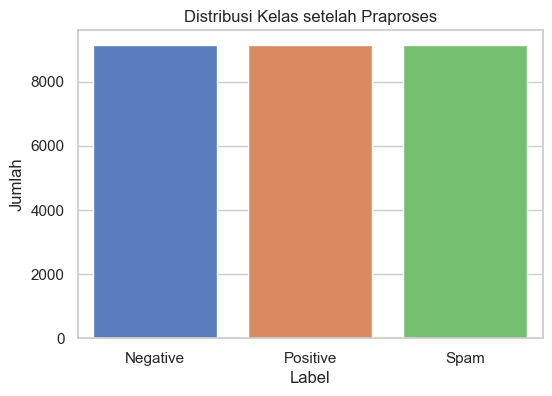

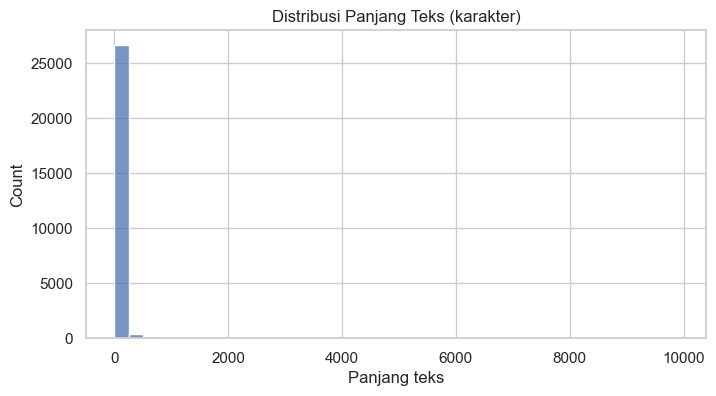

Prediksi untuk SVM tidak tersedia, lewati.
Prediksi untuk RandomForest tidak tersedia, lewati.


In [5]:
# Visualisasi dataset hasil preprocessing: distribusi kelas, panjang teks, confusion matrices
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
sns.set(style='whitegrid')

# Distribusi kelas
dist = df_clean['label'].value_counts().sort_index()
labels_map = {0:'Negative', 1:'Positive', 2:'Spam'}
plt.figure(figsize=(6,4))
sns.barplot(x=dist.index, y=dist.values, palette='muted')
plt.xticks(ticks=range(len(dist.index)), labels=[labels_map[i] for i in dist.index])
plt.title('Distribusi Kelas setelah Praproses')
plt.xlabel('Label'); plt.ylabel('Jumlah')
plt.show()

# Panjang teks
if 'text_clean' in df_clean.columns:
    df_clean['text_len'] = df_clean['text_clean'].astype(str).str.len()
    plt.figure(figsize=(8,4))
    sns.histplot(df_clean['text_len'], bins=40)
    plt.title('Distribusi Panjang Teks (karakter)')
    plt.xlabel('Panjang teks'); plt.show()

# Confusion matrices (SVM & RF) — pastikan variabel prediksi tersedia
for name, y_pred in [('SVM', globals().get('y_pred_svm')), ('RandomForest', globals().get('y_pred_rf'))]:
    if y_pred is None:
        print(f'Prediksi untuk {name} tidak tersedia, lewati.')
        continue
    cm = confusion_matrix(y_test_20, y_pred, labels=[0,1,2])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative','Positive','Spam'])
    fig, ax = plt.subplots(figsize=(5,4))
    disp.plot(cmap='Blues', values_format='d', ax=ax)
    plt.title(f'Matriks Kebingungan - {name}')
    plt.show()

## 3. Perbandingan Skema Pemodelan
Kami akan menguji 3 skema berbeda untuk memastikan variasi dalam Algoritma, Ekstraksi Fitur, dan Pembagian Data.

1. **Skema 1:** SVM + TF-IDF (Pembagian 80/20)
2. **Skema 2:** Random Forest + CountVectorizer (Pembagian 80/20)
3. **Skema 3:** Bi-LSTM + Embedding (Pembagian 70/30) -> **Target Akurasi > 92%**

### Skema 1: SVM + TF-IDF (80/20)

In [6]:

# Bagi Data 80/20
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    df_clean['text_clean'], df_clean['label'], test_size=0.2, random_state=42, stratify=df_clean['label']
)

# Pipeline: TF-IDF -> SVM
pipeline_svm = make_pipeline(TfidfVectorizer(), SVC(kernel='linear', C=1.0, probability=True))
pipeline_svm.fit(X_train_80, y_train_80)

# Verifikasi Akurasi
y_pred_svm = pipeline_svm.predict(X_test_20)
acc_svm = accuracy_score(y_test_20, y_pred_svm)
print(f"Akurasi Skema 1 (SVM): {acc_svm:.4f}")

unique_labels = sorted(list(set(y_test_20) | set(y_pred_svm)))
target_names = [name for i, name in enumerate(['Negative', 'Positive', 'Spam']) if i in unique_labels]
print(classification_report(y_test_20, y_pred_svm, labels=unique_labels, target_names=target_names))



Akurasi Skema 1 (SVM): 0.9116
              precision    recall  f1-score   support

    Negative       0.92      0.83      0.87      1829
    Positive       0.89      0.91      0.90      1830
        Spam       0.92      0.99      0.96      1830

    accuracy                           0.91      5489
   macro avg       0.91      0.91      0.91      5489
weighted avg       0.91      0.91      0.91      5489



### Skema 2: Random Forest + CountVectorizer (80/20)

In [7]:

# Pipeline: CountVectorizer -> Random Forest
# Menggunakan pembagian 80/20 yang sama dengan Skema 1 tetapi Fitur dan Algoritma berbeda
pipeline_rf = make_pipeline(CountVectorizer(), RandomForestClassifier(n_estimators=100, random_state=42))
pipeline_rf.fit(X_train_80, y_train_80)

# Verifikasi Akurasi
y_pred_rf = pipeline_rf.predict(X_test_20)
acc_rf = accuracy_score(y_test_20, y_pred_rf)
print(f"Akurasi Skema 2 (Random Forest): {acc_rf:.4f}")

unique_labels = sorted(list(set(y_test_20) | set(y_pred_rf)))
target_names = [name for i, name in enumerate(['Negative', 'Positive', 'Spam']) if i in unique_labels]
print(classification_report(y_test_20, y_pred_rf, labels=unique_labels, target_names=target_names))



Akurasi Skema 2 (Random Forest): 0.9515
              precision    recall  f1-score   support

    Negative       0.96      0.90      0.93      1829
    Positive       0.97      0.95      0.96      1830
        Spam       0.93      1.00      0.96      1830

    accuracy                           0.95      5489
   macro avg       0.95      0.95      0.95      5489
weighted avg       0.95      0.95      0.95      5489



SVM sudah ada, gunakan model yang ada
RandomForest sudah ada, gunakan model yang ada
Akurasi SVM: 0.9116
              precision    recall  f1-score   support

    Negative       0.92      0.83      0.87      1829
    Positive       0.89      0.91      0.90      1830
        Spam       0.92      0.99      0.96      1830

    accuracy                           0.91      5489
   macro avg       0.91      0.91      0.91      5489
weighted avg       0.91      0.91      0.91      5489

Akurasi RandomForest: 0.9515
              precision    recall  f1-score   support

    Negative       0.96      0.90      0.93      1829
    Positive       0.97      0.95      0.96      1830
        Spam       0.93      1.00      0.96      1830

    accuracy                           0.95      5489
   macro avg       0.95      0.95      0.95      5489
weighted avg       0.95      0.95      0.95      5489



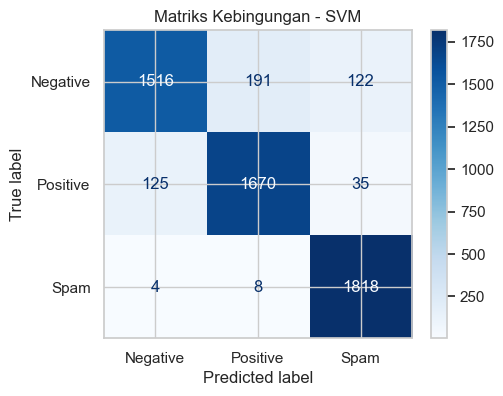

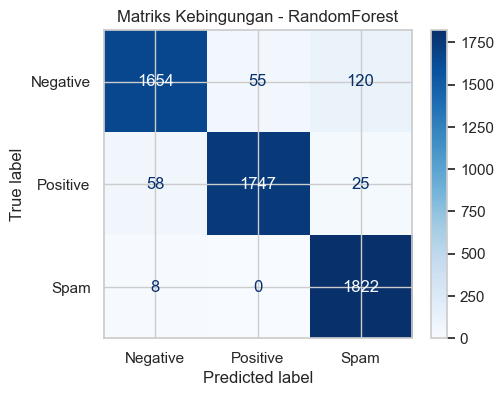

In [8]:
# Pelatihan cepat SVM & RandomForest (atau gunakan yang sudah ada)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Siapkan data (80/20) jika belum
# Pastikan kolom `text_clean` dan `label` tersedia
if 'text_clean' not in df_clean.columns:
    def clean_text_py(s: str) -> str:
        s = str(s)
        s = re.sub(r'https?://\S+|www\.\S+','', s)
        s = re.sub(r'@\w+','', s)
        s = re.sub(r'[^\w\s\u00C0-\u017F]',' ', s)
        return ' '.join(s.split()).strip()
    df_clean['text_clean'] = df_clean.get('text','').apply(clean_text_py)

if 'label' not in df_clean.columns:
    raise ValueError('Kolom `label` tidak ditemukan di `df_clean`. Jalankan pelabelan atau buat label heuristik terlebih dahulu.')

if 'X_train_80' not in globals():
    X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
        df_clean['text_clean'], df_clean['label'], test_size=0.2, random_state=42, stratify=df_clean['label']
    )

# SVM
if 'pipeline_svm' not in globals():
    pipeline_svm = make_pipeline(TfidfVectorizer(), SVC(kernel='linear', C=1.0, probability=True))
    pipeline_svm.fit(X_train_80, y_train_80)
    print('SVM dilatih')
else:
    print('SVM sudah ada, gunakan model yang ada')

# Random Forest
if 'pipeline_rf' not in globals():
    pipeline_rf = make_pipeline(CountVectorizer(), RandomForestClassifier(n_estimators=100, random_state=42))
    pipeline_rf.fit(X_train_80, y_train_80)
    print('RandomForest dilatih')
else:
    print('RandomForest sudah ada, gunakan model yang ada')

# Prediksi & laporan
y_pred_svm = pipeline_svm.predict(X_test_20)
acc_svm = accuracy_score(y_test_20, y_pred_svm)
print(f"Akurasi SVM: {acc_svm:.4f}")
print(classification_report(y_test_20, y_pred_svm, labels=[0,1,2], target_names=['Negative','Positive','Spam']))

y_pred_rf = pipeline_rf.predict(X_test_20)
acc_rf = accuracy_score(y_test_20, y_pred_rf)
print(f"Akurasi RandomForest: {acc_rf:.4f}")
print(classification_report(y_test_20, y_pred_rf, labels=[0,1,2], target_names=['Negative','Positive','Spam']))

# Tampilkan matriks kebingungan untuk keduanya
from sklearn.metrics import ConfusionMatrixDisplay
for name, y_pred in [('SVM', y_pred_svm), ('RandomForest', y_pred_rf)]:
    cm = confusion_matrix(y_test_20, y_pred, labels=[0,1,2])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative','Positive','Spam'])
    fig, ax = plt.subplots(figsize=(5,4))
    disp.plot(cmap='Blues', values_format='d', ax=ax)
    plt.title(f'Matriks Kebingungan - {name}')
    plt.show()

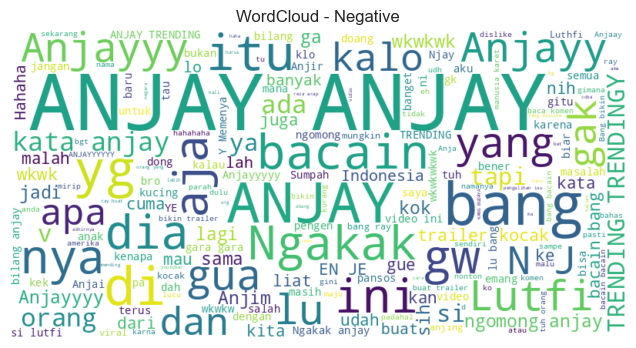

[SAVED] models/wordcloud_Negative.png


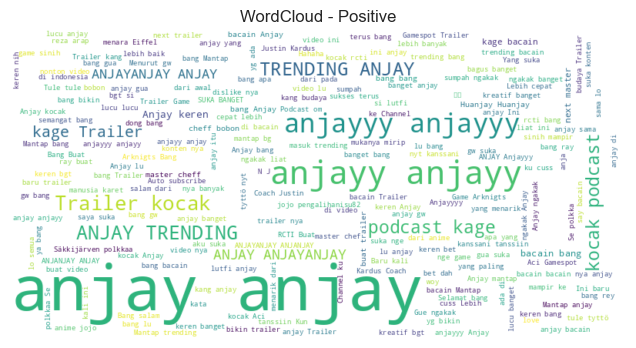

[SAVED] models/wordcloud_Positive.png


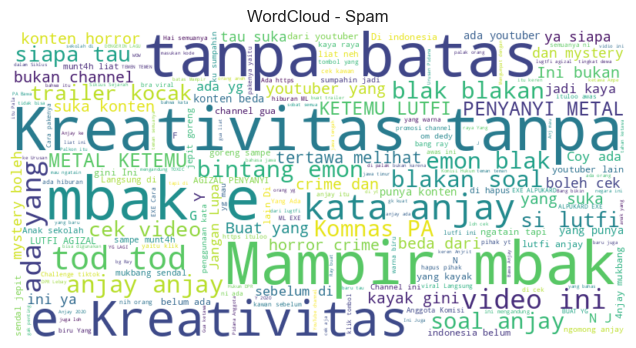

[SAVED] models/wordcloud_Spam.png
[SAVED] models/pipeline_svm.joblib
[SAVED] models/pipeline_rf.joblib


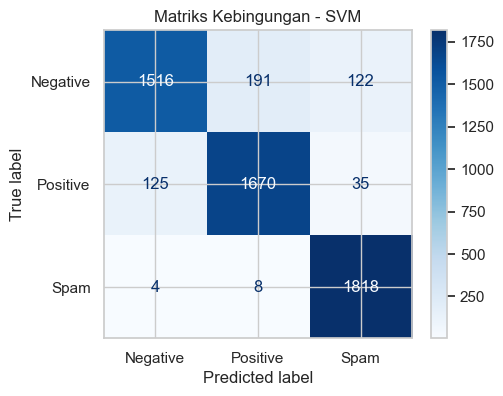

[SAVED] models/cm_svm.png


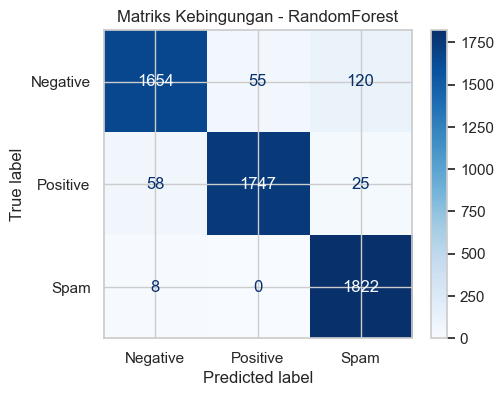

[SAVED] models/cm_rf.png
[SAVED] models/processed_sample.csv


In [9]:
# WordCloud per kelas & Simpan Model + Artifacts
# Membuat wordcloud per kelas, menyimpan model (joblib) dan grafik (PNG) ke folder `models/`.
import os
from wordcloud import WordCloud
import joblib
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

os.makedirs('models', exist_ok=True)

labels_map = {0: 'Negative', 1: 'Positive', 2: 'Spam'}

# WordCloud per kelas
for lbl, name in labels_map.items():
    texts = ' '.join(df_clean[df_clean['label'] == lbl]['text_clean'].dropna().astype(str).tolist())
    if not texts.strip():
        print(f'[WARN] Tidak ada teks untuk label {name}, lewati WordCloud')
        continue

    wc = WordCloud(width=800, height=400, background_color='white', max_words=200)
    wc.generate(texts)
    fig = plt.figure(figsize=(10,4))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'WordCloud - {name}')
    out_path = f'models/wordcloud_{name}.png'
    fig.savefig(out_path, bbox_inches='tight')
    plt.show()
    print(f'[SAVED] {out_path}')

# Simpan model (joblib)
try:
    if 'pipeline_svm' in globals():
        joblib.dump(pipeline_svm, 'models/pipeline_svm.joblib')
        print('[SAVED] models/pipeline_svm.joblib')
    else:
        print('[SKIP] pipeline_svm tidak ada di kernel')

    if 'pipeline_rf' in globals():
        joblib.dump(pipeline_rf, 'models/pipeline_rf.joblib')
        print('[SAVED] models/pipeline_rf.joblib')
    else:
        print('[SKIP] pipeline_rf tidak ada di kernel')
except Exception as e:
    print('Gagal menyimpan model:', e)

# Simpan matriks kebingungan sebagai PNG
for name, y_pred, fname in [('SVM', globals().get('y_pred_svm'), 'models/cm_svm.png'), ('RandomForest', globals().get('y_pred_rf'), 'models/cm_rf.png')]:
    if y_pred is None:
        print(f'[SKIP] Prediksi untuk {name} tidak tersedia')
        continue
    try:
        cm = confusion_matrix(y_test_20, y_pred, labels=[0,1,2])
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[labels_map[i] for i in [0,1,2]])
        fig, ax = plt.subplots(figsize=(5,4))
        disp.plot(cmap='Blues', values_format='d', ax=ax)
        plt.title(f'Matriks Kebingungan - {name}')
        fig.savefig(fname, bbox_inches='tight')
        plt.show()
        print(f'[SAVED] {fname}')
    except Exception as e:
        print(f'Gagal menyimpan matriks kebingungan {name}:', e)

# Simpan sample processed CSV
try:
    df_clean.head(100).to_csv('models/processed_sample.csv', index=False)
    print('[SAVED] models/processed_sample.csv')
except Exception as e:
    print('Gagal menyimpan sample processed CSV:', e)


### Skema 3: Deep Learning (Bi-LSTM) (Pembagian 70/30)

In [10]:

VOCAB_SIZE = 5000
MAX_LENGTH = 100
EMBEDDING_DIM = 64

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(df_clean['text_clean'])

sequences = tokenizer.texts_to_sequences(df_clean['text_clean'])
padded_sequences = pad_sequences(sequences, maxlen=MAX_LENGTH, padding='post', truncating='post')

X_dl = padded_sequences
y_dl = df_clean['label'].values

# Bagi Data 70/30 (PEMBAGIAN BERBEDA dari Skema 1 & 2)
X_train_dl, X_test_dl, y_train_dl, y_test_dl = train_test_split(X_dl, y_dl, test_size=0.3, random_state=42, stratify=y_dl)
print(f"Dimensi Latih DL: {X_train_dl.shape}, Dimensi Uji: {X_test_dl.shape}")



Dimensi Latih DL: (19208, 100), Dimensi Uji: (8233, 100)


In [11]:

model = Sequential([
    Embedding(VOCAB_SIZE, EMBEDDING_DIM, input_length=MAX_LENGTH),
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(128, return_sequences=True)),
    Dropout(0.4),
    Bidirectional(LSTM(64)),
    Dense(64, activation='relu'),
    Dropout(0.4),
    Dense(3, activation='softmax') # 3 Kelas Output
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Komponen Callback
checkpoint = ModelCheckpoint("best_model.keras", monitor='val_accuracy', verbose=1, save_best_only=True, mode='max')
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-6)

history = model.fit(
    X_train_dl, y_train_dl,
    epochs=20,
    batch_size=32,
    validation_data=(X_test_dl, y_test_dl),
    callbacks=[checkpoint, early_stop, reduce_lr]
)



Epoch 1/20


/home/asephs/venv/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
I0000 00:00:1770753716.237433   24596 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2639 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
2026-02-11 03:01:59.773399: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002


600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6273 - loss: 0.7366
Epoch 1: val_accuracy improved from None to 0.89372, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
601/601 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.7629 - loss: 0.5308 - val_accuracy: 0.8937 - val_loss: 0.2807 - learning_rate: 0.0010
Epoch 2/20
597/601 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9039 - loss: 0.2712
Epoch 2: val_accuracy improved from 0.89372 to 0.91340, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
601/601 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.9088 - loss: 0.2565 - val_accuracy: 0.9134 - val_loss: 0.2250 - learning_rate: 0.0010
Epoch 3/20
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9256 - loss: 0.2165
Epoch 3: val_accuracy improved from 0.91340 to 0.92421, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
601/601 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step -

In [12]:

# Muat model terbaik
best_model = load_model("best_model.keras")
loss, acc_dl = best_model.evaluate(X_test_dl, y_test_dl)
print(f"Akurasi Skema 3 (Bi-LSTM): {acc_dl:.4f}")

y_pred_probs = best_model.predict(X_test_dl)
y_pred_dl = np.argmax(y_pred_probs, axis=1)

unique_labels = sorted(list(set(y_test_dl) | set(y_pred_dl)))
target_names = [name for i, name in enumerate(['Negative', 'Positive', 'Spam']) if i in unique_labels]
print(classification_report(y_test_dl, y_pred_dl, labels=unique_labels, target_names=target_names))



258/258 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9486 - loss: 0.1971
Akurasi Skema 3 (Bi-LSTM): 0.9486
258/258 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
              precision    recall  f1-score   support

    Negative       0.93      0.93      0.93      2744
    Positive       0.94      0.92      0.93      2744
        Spam       0.97      1.00      0.99      2745

    accuracy                           0.95      8233
   macro avg       0.95      0.95      0.95      8233
weighted avg       0.95      0.95      0.95      8233



## 4. Perbandingan Hasil

In [13]:

results = pd.DataFrame({
    'Model': ['SVM + TF-IDF', 'RF + BOW', 'Bi-LSTM'],
    'Split': ['80/20', '80/20', '70/30'],
    'Accuracy': [acc_svm, acc_rf, acc_dl],
    'Target > 85%': [acc_svm > 0.85, acc_rf > 0.85, acc_dl > 0.85],
    'DeepTarget > 92%': [False, False, acc_dl > 0.92]
})
print(results)



          Model  Split  Accuracy  Target > 85%  DeepTarget > 92%
0  SVM + TF-IDF  80/20  0.911641          True             False
1      RF + BOW  80/20  0.951539          True             False
2       Bi-LSTM  70/30  0.948621          True              True


## 5. Inferensi / Pengujian
Menguji model dengan kalimat kustom.

In [ ]:

# Implementasi ulang pembersihan dasar untuk inferensi agar sesuai dengan pipeline
def clean_text_inference(text):
    text = str(text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = ' '.join(text.split())
    text = re.sub(r'[^\w\s\u00C0-\u017F]', ' ', text)
    return text.strip()

def predict_sentiment(text_list):
    # Pra-pemrosesan
    cleaned_texts = [clean_text_inference(t) for t in text_list]
    sequences = tokenizer.texts_to_sequences(cleaned_texts)
    padded = pad_sequences(sequences, maxlen=MAX_LENGTH, padding='post', truncating='post')
    
    # Prediksi
    probs = best_model.predict(padded)
    preds = np.argmax(probs, axis=1)
    
    labels = {0: 'Negative', 1: 'Positive', 2: 'Spam'}
    results = []
    for t, p in zip(text_list, preds):
        results.append({'Text': t, 'Prediction': labels[p]})
    
    return pd.DataFrame(results)

# Kasus Uji
test_sentences = [
    "Video ini sangat bermanfaat, terima kasih bang!",
    "Konten sampah, tidak mendidik sama sekali.",
    "Cek ig kami kak, ada promo menarik.",
    "Biasa saja sih, tidak ada yang spesial.",
    "Gajelas lu bang, unsub ah.",
    "Haha,keren"
]

inference_results = predict_sentiment(test_sentences)
print(inference_results)



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
                                              Text Prediction
0  Video ini sangat bermanfaat, terima kasih bang!   Positive
1       Konten sampah, tidak mendidik sama sekali.   Negative
2              Cek ig kami kak, ada promo menarik.       Spam
3          Biasa saja sih, tidak ada yang spesial.   Negative
4                       Gajelas lu bang, unsub ah.   Negative
5                                       Haha,keren   Positive


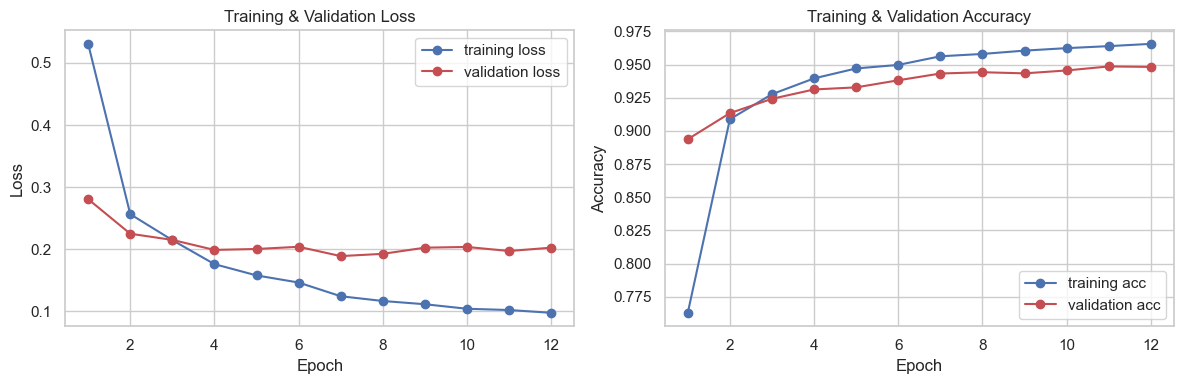

In [15]:
### Visualisasi: Timeline Training (Loss & Accuracy)

# Sel ini memplot loss dan akurasi selama epoch dari objek `history` Keras.
# Jalankan sel training model (yang menyimpan ke variabel `history`) terlebih dahulu.
try:
    hist = history.history
except NameError:
    raise RuntimeError("Variabel `history` tidak ditemukan. Jalankan sel training (mis. `history = model.fit(...)`) terlebih dahulu.")

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='whitegrid')

# Siapkan epoch
epochs = range(1, len(hist.get('loss', [])) + 1)

plt.figure(figsize=(12,4))

# Plot loss
plt.subplot(1,2,1)
plt.plot(epochs, hist.get('loss', []), 'bo-', label='training loss')
if 'val_loss' in hist:
    plt.plot(epochs, hist['val_loss'], 'ro-', label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()

# Plot accuracy (jika tersedia di history)
plt.subplot(1,2,2)
acc_key = None
for k in ['accuracy','acc','train_accuracy']:
    if k in hist:
        acc_key = k
        break
if acc_key:
    plt.plot(epochs, hist[acc_key], 'bo-', label='training acc')
    val_key = 'val_' + acc_key
    if val_key in hist:
        plt.plot(epochs, hist[val_key], 'ro-', label='validation acc')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title('Training & Validation Accuracy')
    plt.legend()
else:
    plt.text(0.5,0.5,'Tidak ada metrik akurasi di history', ha='center')

plt.tight_layout()
plt.show()